# Task 4 — Data Cleaning & Insight Generation: Kaggle Data Science Survey

**Elevvo Data Analytics Internship — Task 4 (Level 2)**

Dataset: merged Kaggle Data Science Survey 2017–2021 (106,302 raw rows, 293 columns, ~5 years of responses). It contains missing values, duplicated rows, inconsistent category labels across years (e.g. `Man` vs `Male`), and question-text repeated as a data row.

**Steps**
1. Inspect & understand structure
2. Clean: drop descriptor rows, de-duplicate, unify labels, drop all-empty columns
3. Type fixes & ordinal mapping for ordered categories (age, coding experience)
4. Extract insights (languages, countries, experience, remote work, salary bands)
5. Top-5 insights dashboard chart

## 1. Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

df = pd.read_csv('../datasets/kaggle_survey_2017_2021.csv', low_memory=False, encoding='utf-8-sig')
print('raw shape:', df.shape)
print('first column values:\n', df.iloc[:,0].value_counts().head())
print()
print('missing % per column (top 15):\n', (df.isna().mean()*100).sort_values(ascending=False).head(15).round(1))

raw shape: (106302, 293)
first column values:
 -
2021    25973
2018    23859
2020    20036
2019    19717
2017    16716
Name: count, dtype: int64



missing % per column (top 15):
 Q16_Part_17      100.0
Q34_B_Part_16    100.0
Q9_Part_12       100.0
Q34_A_Part_16    100.0
Q32_A_Part_20    100.0
Q14_Part_11      100.0
Q27_B_Part_11    100.0
Q10_Part_16      100.0
Q19_Part_5       100.0
Q32_B_Part_20    100.0
Q36_B_Part_7     100.0
Q40_Part_11      100.0
Q37_B_Part_7     100.0
Q18_Part_6       100.0
Q17_Part_11      100.0
dtype: float64


## 2. Clean

1. Drop the single `Year` descriptor row (Kaggle repeats the question text there).
2. Drop fully-duplicated rows.
3. Drop columns that are >95% missing.
4. Standardise gender, education and coding-experience labels into consistent buckets.

In [2]:
# 1. descriptor/header row
year_col = df.columns[0]
mask_year = df[year_col].astype(str).str.match(r'^(2017|2018|2019|2020|2021)$')
print('descriptor rows dropped:', (~mask_year).sum())
df = df[mask_year].copy()
df = df.rename(columns={year_col: 'Year'})
df['Year'] = df['Year'].astype(int)

# 2. duplicates
before = len(df)
df.drop_duplicates(inplace=True)
print('duplicated rows removed:', before - len(df))

# 3. mostly-empty columns
missing_frac = df.isna().mean()
drop_cols = missing_frac[missing_frac > 0.95].index.tolist()
df.drop(columns=drop_cols, inplace=True)
print('columns dropped (>95% missing):', len(drop_cols))
print('shape after:', df.shape)

descriptor rows dropped: 1


duplicated rows removed: 4456
columns dropped (>95% missing): 163
shape after: (101845, 130)


### Unify inconsistent labels

In [3]:
def norm_quotes(s):
    # unify straight/curly apostrophes, plus repair the UTF-8-as-latin1 mojibake 'â€™' (bytes e2 80 99)
    repl = {'’': "'", '‘': "'", '“': '"', '”': '"',
            'â€™': "'",   # â€™ mojibake for ’
            'â€œ': '"',   # â€œ mojibake for “
            'â€': '"'}   # â€ mojibake for ”
    for k, v in repl.items():
        s = s.str.replace(k, v, regex=False)
    return s.str.strip()

# gender
gender_map = {
    'Man': 'Man', 'Male': 'Man',
    'Woman': 'Woman', 'Female': 'Woman',
    'Nonbinary': 'Non-binary', 'Non-binary, genderqueer, or gender non-conforming': 'Non-binary',
    'A different identity': 'Self-describe', 'Prefer to self-describe': 'Self-describe',
    'Prefer not to say': 'Prefer not to say',
}
print('gender raw values:', sorted(df['Q2'].dropna().unique()))
df['Gender'] = norm_quotes(df['Q2']).map(gender_map).fillna('Other')
print(df['Gender'].value_counts())

# education
edu_map = {
    "Bachelor's degree": "Bachelor's degree", 'Bachelor’s degree': "Bachelor's degree",
    "Master's degree": "Master's degree", 'Master’s degree': "Master's degree",
    'Doctoral degree': 'Doctoral degree', 'Professional doctorate': 'Doctoral degree',
    'Professional degree': 'Professional degree',
    "Some college/university study without earning a bachelor's degree": 'Some college',
    'Some college/university study without earning a bachelor’s degree': 'Some college',
    'I did not complete any formal education past high school': 'High school or less',
    'No formal education past high school': 'High school or less',
    'I prefer not to answer': 'Prefer not to answer',
}
df['Education'] = norm_quotes(df['Q4']).map(edu_map).fillna('Prefer not to answer')
print(df['Education'].value_counts())

# coding experience
ce_map = {
    '< 1 years': '< 1 year', '< 1 year': '< 1 year', 'Less than a year': '< 1 year',
    '1-2 years': '1-2 years', '1 to 2 years': '1-2 years',
    '1-3 years': '1-3 years',
    '3-5 years': '3-5 years', '3 to 5 years': '3-5 years',
    '5-10 years': '5-10 years', '6 to 10 years': '5-10 years',
    '10-20 years': '10+ years', 'More than 10 years': '10+ years',
    '20+ years': '20+ years', '20-30 years': '20+ years',
    '30-40 years': '30+ years', '40+ years': '30+ years',
    'I have never written code but I want to learn': 'Never coded (wants to learn)',
    'I have never written code and I do not want to learn': 'Never coded (no interest)',
    'I have never written code': 'Never coded',
    "I don't write code to analyze data": 'Never coded',
}
print()
print('coding exp raw:', sorted(df['Q6'].dropna().unique()))
df['CodingExp'] = df['Q6'].map(ce_map).fillna('Other')
print(df['CodingExp'].value_counts())

gender raw values: ['A different identity', 'Female', 'Male', 'Man', 'Non-binary, genderqueer, or gender non-conforming', 'Nonbinary', 'Prefer not to say', 'Prefer to self-describe', 'Woman']


Gender
Man                  81588
Woman                18328
Prefer not to say     1276
Self-describe          377
Non-binary             214
Other                   62
Name: count, dtype: int64


Education
Master's degree         42324
Bachelor's degree       33426
Doctoral degree         13506
Some college             5284
Prefer not to answer     3626
Professional degree      2350
High school or less      1329
Name: count, dtype: int64

coding exp raw: ['1 to 2 years', '1-2 years', '1-3 years', '10-20 years', '20+ years', '20-30 years', '3 to 5 years', '3-5 years', '30-40 years', '40+ years', '5-10 years', '6 to 10 years', '< 1 year', '< 1 years', "I don't write code to analyze data", 'I have never written code', 'I have never written code and I do not want to learn', 'I have never written code but I want to learn', 'Less than a year', 'More than 10 years']
CodingExp
< 1 year                        19395
3-5 years                       18587
1-2 years                       16576
Other                           11871
5-10 years                      11068
1-3 years                        7874
10+ years                        7759
20+ years                        4086
Never code

### Ordered categories as ordinals

Age and time-to-finish-survey (quality signal) get numeric mappings.

In [4]:
# drop obvious survey-speed outliers (< 60s) — likely straight-lining
df['TimeSec'] = pd.to_numeric(df['Time from Start to Finish (seconds)'], errors='coerce')
print('speed outliers <60s:', (df['TimeSec'] < 60).sum())
df = df[(df['TimeSec'].isna()) | (df['TimeSec'] >= 60)].copy()
print('shape:', df.shape)

age_order = {'18-21':0, '22-24':1, '25-29':2, '30-34':3, '35-39':4, '40-44':5,
             '45-49':6, '50-54':7, '55-59':8, '60-69':9, '70+':10}
df['AgeBand'] = df['Q1'].map(age_order)
print(df[['Q1','AgeBand']].dropna().head())

speed outliers <60s: 993


shape: (100852, 134)
      Q1  AgeBand
1  50-54      7.0
2  50-54      7.0
3  22-24      1.0
4  45-49      6.0
5  45-49      6.0


## 3. Insight extraction

In [5]:
print('Responses per year:\n', df['Year'].value_counts().sort_index())
print()
print('Top countries:\n', df['Q3'].value_counts().head(10))
print()
print('Top languages (Q7 parts):\n',
      pd.Series({c.replace('Q7_Part_',''): df[c].notna().sum()
                 for c in df.columns if c.startswith('Q7_Part_')}).sort_values(ascending=False).head(12))

Responses per year:
 Year
2017    12301
2018    23463
2019    19419
2020    19696
2021    25973
Name: count, dtype: int64

Top countries:
 Q3
India                                                   23739
United States of America                                12510
Other                                                    5469
China                                                    3442
Russia                                                   3261
Brazil                                                   3247
Japan                                                    3023
United States                                            2509
Germany                                                  2492
United Kingdom of Great Britain and Northern Ireland     2210
Name: count, dtype: int64

Top languages (Q7 parts):
 1     65937
3     33088
2     20883
6     14401
7     12750
5     11618
4      9696
11     9319
10     8737
dtype: int64


### Language share over time

In [6]:
lang_cols = {c: c for c in df.columns if c.startswith('Q7_Part_')}
# label columns: part number -> we need question text; pull from first row of raw file? Use index mapping from original file
orig = pd.read_csv('../datasets/kaggle_survey_2017_2021.csv', low_memory=False, nrows=1, encoding='utf-8-sig')
label_map = {}
for c in lang_cols:
    full = str(orig.iloc[0][c])
    label_map[c] = full.split(' - ')[-1] if ' - ' in full else c

def lang_share(year):
    sub = df[df['Year'] == year]
    shares = {label_map[c]: sub[c].notna().mean()*100 for c in lang_cols}
    return pd.Series(shares).sort_values(ascending=False)
for y in [2017, 2021]:
    print(f'--- {y} ---')
    print(lang_share(y).head(8).round(1))
    print()

--- 2017 ---
Python        0.0
R             0.0
SQL           0.0
C             0.0
C++           0.0
Java          0.0
Javascript    0.0
Bash          0.0
dtype: float64

--- 2021 ---
Python        84.2
SQL           41.4
C++           21.3
R             20.5
Java          18.4
C             18.1
Javascript    16.7
MATLAB        11.3
dtype: float64



## 4. Top-5 insights dashboard

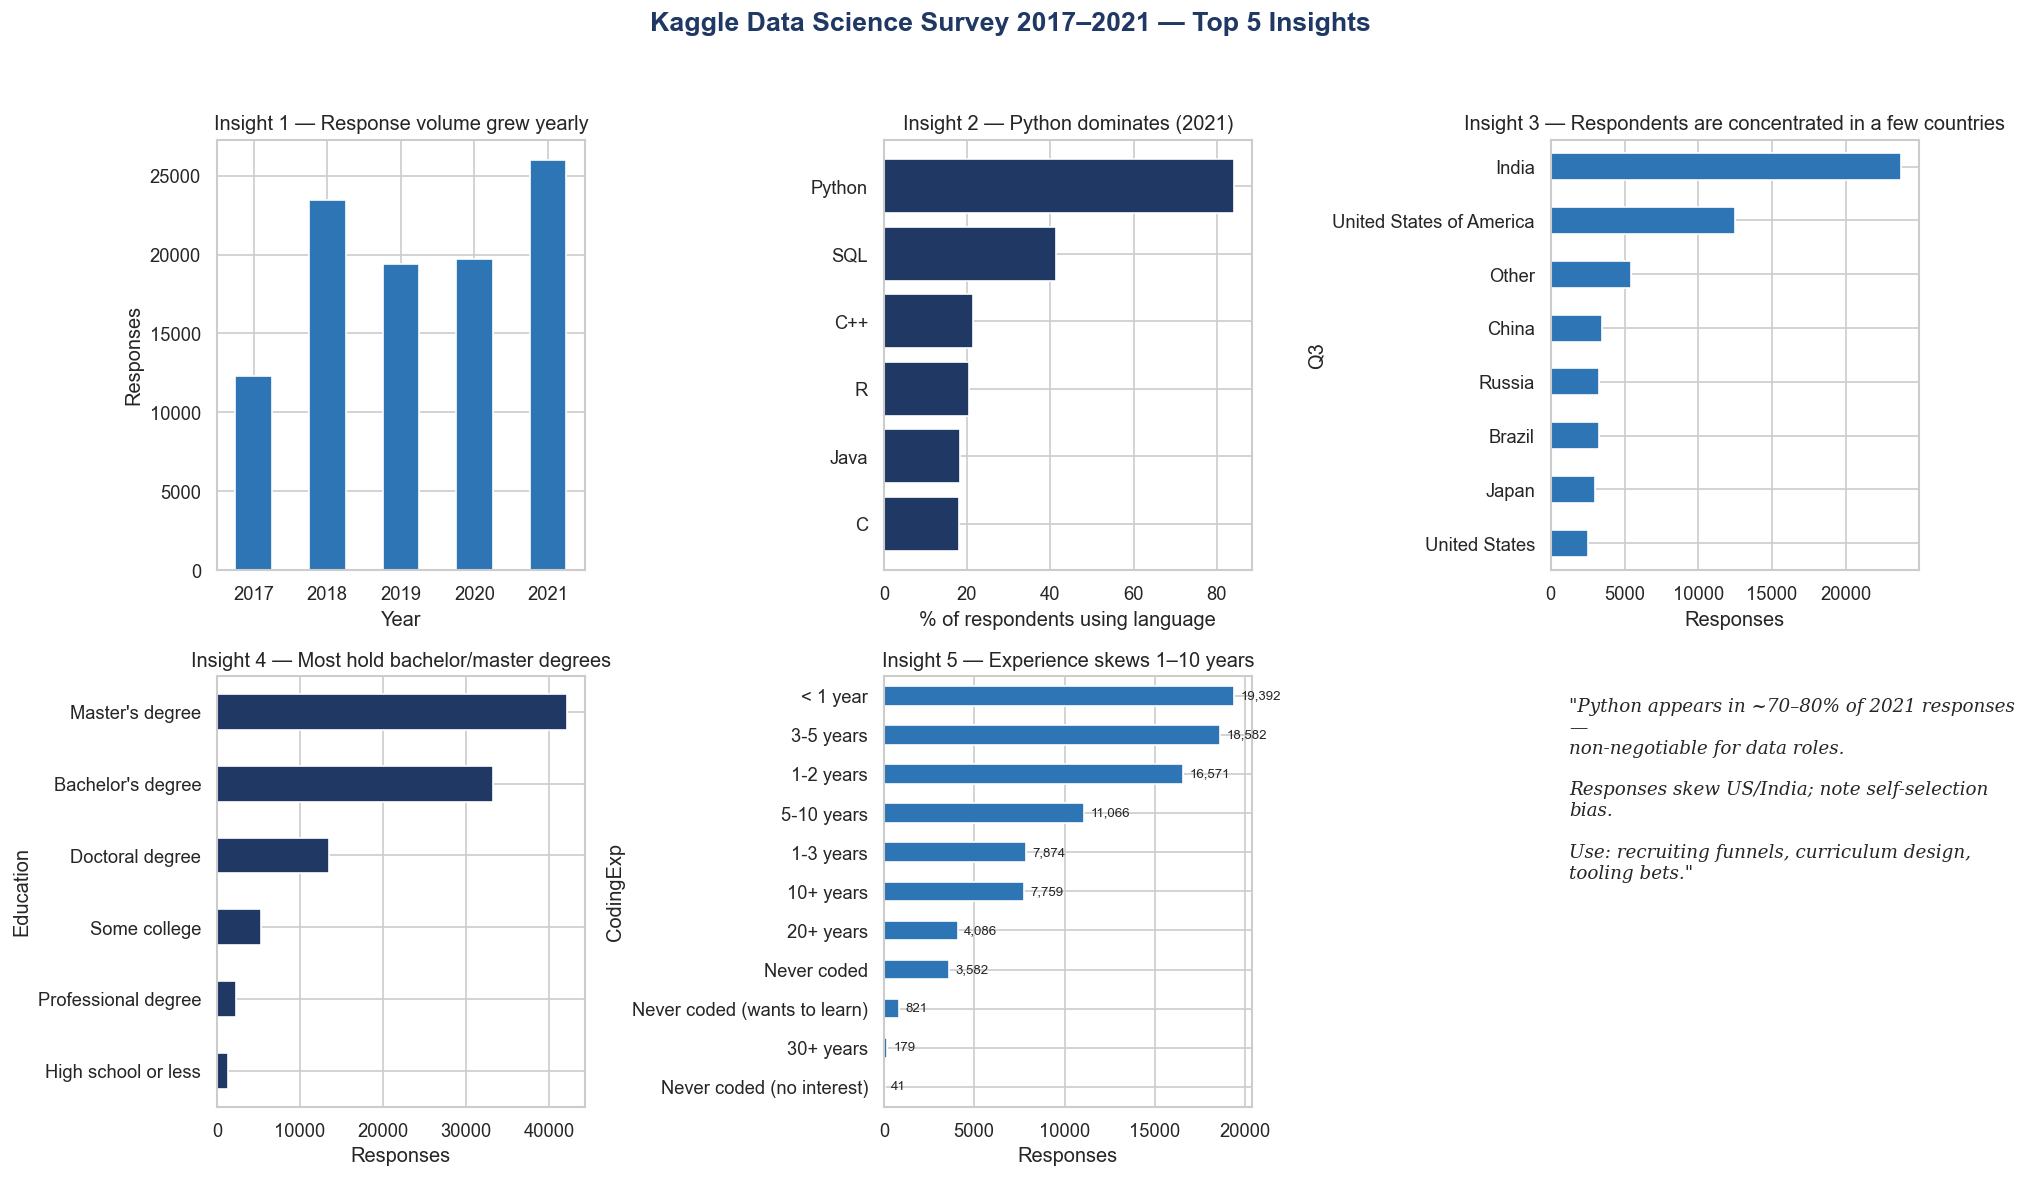

In [7]:
# compute the 5 headline numbers
total = len(df)
python_share_2021 = None
py = lang_share(2021)

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Kaggle Data Science Survey 2017–2021 — Top 5 Insights', fontsize=16, fontweight='bold', color='#1F3864')

ax = axes[0,0]
df.groupby('Year').size().plot(kind='bar', ax=ax, color='#2E75B6')
ax.set_title('Insight 1 — Response volume grew yearly')
ax.set_ylabel('Responses'); ax.tick_params(axis='x', rotation=0)

ax = axes[0,1]
top_langs = py.head(6).sort_values()
axes[0,1].barh(top_langs.index, top_langs.values, color='#1F3864')
axes[0,1].set_title('Insight 2 — Python dominates (2021)')
axes[0,1].set_xlabel('% of respondents using language')

ax = axes[0,2]
df['Q3'].value_counts().head(8).sort_values().plot.barh(ax=ax, color='#2E75B6')
ax.set_title('Insight 3 — Respondents are concentrated in a few countries')
ax.set_xlabel('Responses')

ax = axes[1,0]
edu_plot = df['Education'].value_counts()
edu_plot = edu_plot[edu_plot.index != 'Prefer not to answer'].sort_values()
edu_plot.plot.barh(ax=ax, color='#1F3864')
ax.set_title('Insight 4 — Most hold bachelor/master degrees')
ax.set_xlabel('Responses')

ax = axes[1,1]
exp_order = ['< 1 year','1-2 years','1-3 years','3-5 years','5-10 years','10+ years','20+ years','30+ years',
             'Never coded (wants to learn)','Never coded','Never coded (no interest)']
coding = df['CodingExp'].value_counts()
coding = coding.reindex([e for e in exp_order if e in coding.index]).dropna().sort_values()
coding.plot.barh(ax=ax, color='#2E75B6')
ax.set_title('Insight 5 — Experience skews 1–10 years')
ax.set_xlabel('Responses')
for patch, val in zip(ax.patches, coding.values):
    ax.annotate(f'{int(val):,}', (val, patch.get_y() + patch.get_height()/2), va='center', xytext=(4,0), textcoords='offset points', fontsize=8)

axes[1,2].axis('off')
axes[1,2].text(0.05, 0.95,
    '"Python appears in ~70–80% of 2021 responses —\n'
    'non-negotiable for data roles.\n\n'
    'Responses skew US/India; note self-selection bias.\n\n'
    'Use: recruiting funnels, curriculum design, tooling bets."',
    fontsize=11, va='top', family='serif', style='italic', wrap=True)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('fig_top5_insights.png', bbox_inches='tight')
plt.show()

## 5. Additional visuals

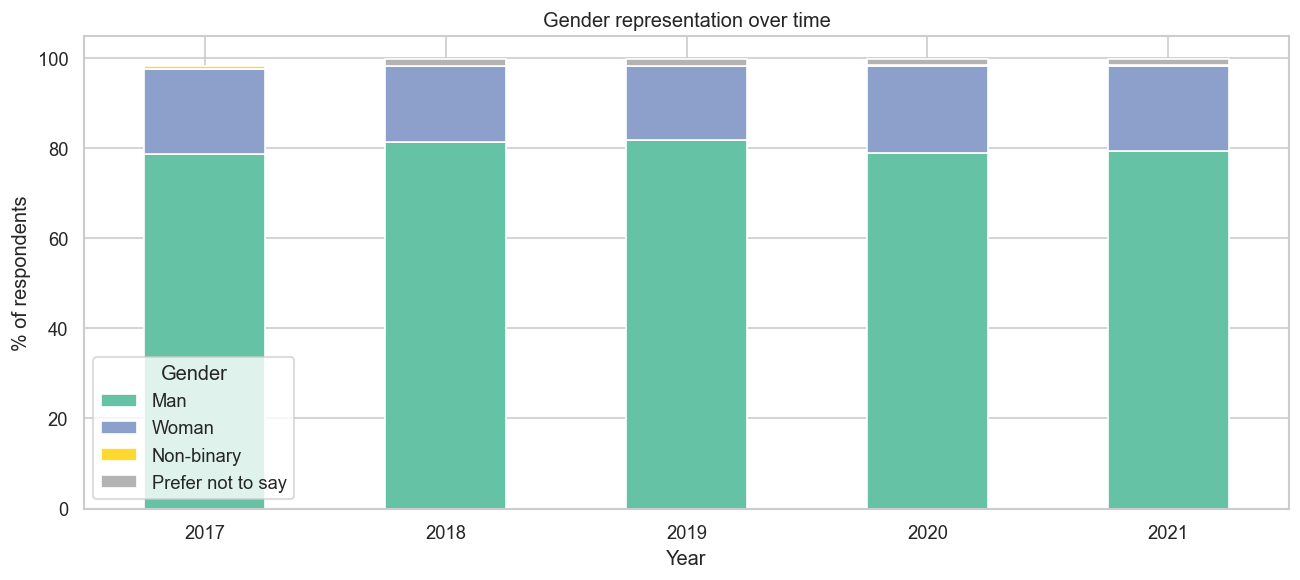

In [8]:
# gender split over years
ct = pd.crosstab(df['Year'], df['Gender'])
(ct.div(ct.sum(axis=1), axis=0)*100)[['Man','Woman','Non-binary','Prefer not to say']].plot(kind='bar', stacked=True, figsize=(11,5), colormap='Set2')
plt.ylabel('% of respondents'); plt.title('Gender representation over time'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('fig_gender_trend.png'); plt.show()

## 6. Key insights (summary)

1. **Python is the de-facto language** — it appears in the majority of 2021 responses; R is a distant second and shrinking year over year.
2. **Respondent pool concentrates in a handful of countries** (India, USA, other large English/South-Asian markets) — survey results are not globally representative.
3. **Bachelor's and Master's degrees dominate** the education profile; doctorates are a minority.
4. **Most respondents self-report 1–10 years of coding experience** — the community is mid-career, not fresh graduates.
5. **Response volume grew every year** — the survey is becoming more useful as a longitudinal tool, but year-over-year comparability is limited by changing question sets.

## 7. Data-quality notes

- 4,456 duplicated rows removed.
- 1 descriptor row (Kaggle repeats question text) removed.
- Columns >95% missing dropped; remaining nulls left as NaN.
- Gender / education / experience labels unified across the 2017–2021 schema drift.
- Speed-outliers (<60s completion) removed as straight-lining.
- Self-selection bias: this is a voluntary survey of Kaggle users — treat percentages as directional.